# Student Wellbeing Survey: Preprocessing up to Scaling
**ICT Academy of Kerala · Use-Case Discussion · Solution notebook · Google Colab**
*Topics: Missing Values & Duplicates · Outliers · Encoding · Scaling (StandardScaler)*

**How to use this notebook:** compare it with your own work. It shows **one good way** to explore and prepare the dataset. Your steps may differ. What matters is that every decision has a **reason**.

## The scenario
A university counselling team ran an anonymous survey of **4,464 students** (age, semester, CGPA, family background, living style, health condition, monthly cost and more). The last column, `Depression` (Yes / No), is the survey answer. The data science team wants to prepare this table so a model can use it later. Your job is only the **preparation**: check the quality, handle what needs handling, turn text into numbers and scale the numbers, and **explain each decision**.

> **A note on the data:** this is a practice dataset about a sensitive topic. We use it to learn preprocessing. Nothing here is a medical conclusion about any real student.

## How to start in Colab
Upload `Student_Depression_Dataset.csv` (Files panel on the left > Upload), then run the notebook from top to bottom. If something goes wrong use *Runtime → Restart and run all*.

**Map of exploration to classes**
| Part | What is explored | Class it comes from |
|---|---|---|
| 1 | shape, info, describe, value_counts | pandas basics, descriptive statistics |
| 2 | missing values and duplicates | Missing Values & Duplicates |
| 3 | box plots, IQR, Z-score | Outliers |
| 4 | label encoding (`LabelEncoder`), ordinal encoding (`OrdinalEncoder`) and one-hot encoding (`OneHotEncoder`) | Encoding |
| 5 | StandardScaler | Scaling |

<div style="background:#1a5fb4;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:24px;font-size:20px;font-weight:bold">Part 1 · First look at the data</div>

## 1.1 · Load and look

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)

df = pd.read_csv("Student_Depression_Dataset.csv")
raw = df.copy()          # untouched copy for before / after
print(df.shape)
df.head()

(4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


## 1.2 · Statistics and categories  *(descriptive statistics, value_counts)*

In [ ]:
df.describe().round(2)

,Age,Current_semester,CGPA,Cost_without_study
count,4464.00,4464.00,4464.00,4464.00
mean,22.62,5.40,3.41,11242.98
std,2.02,2.58,0.39,6640.14
min,17.00,0.00,2.25,0.00
25%,21.00,3.00,3.15,6100.00
50%,23.00,5.00,3.49,9500.00
75%,24.00,7.00,3.70,15439.00
max,28.00,13.00,4.00,32000.00


In [ ]:
cat_cols = df.select_dtypes(exclude=["number"]).columns
num_cols = df.select_dtypes(include=["number"]).columns
print("Numerical  :", list(num_cols))
print("Categorical:", list(cat_cols))
print()
for col in cat_cols:
    print(df[col].value_counts(), "\n")

Numerical  : ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Categorical: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division', 'Depression']

Gender
Female    2462
Male      2002
Name: count, dtype: int64 

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64 

Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64 

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64 

Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64 

friend_circle
Yes    3215
No     1249
Name: count, dtype: int64 

Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64 

Home_division
Dhaka         1527
Khulna         548
Rajshahi       488
Sylhet         445

**What to notice:**
* 13 columns: **4 numerical** (Age, Current_semester, CGPA, Cost_without_study) and **9 text** columns.
* Several text columns have only 2 values (Gender, Living_style, friend_circle, Depression); some have 3 (Family_background, Relationship_status, Marital_status), one has 4 (Health_condition) and one has 8 (Home_division).
* The spelling of every category looks consistent: no `Dhaka` / `dhaka` variants.
* The answer column `Depression` is **not balanced**: about 3 in 4 students answered No.

In [ ]:
print(df["Depression"].value_counts(normalize=True).round(3))

Depression
No     0.731
Yes    0.269
Name: proportion, dtype: float64


<div style="background:#b26a00;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:24px;font-size:20px;font-weight:bold">Part 2 · Missing values and duplicates</div>

## 2.1 · Are there missing values?

In [ ]:
print(df.isnull().sum())
print()
print("Total missing values:", int(df.isnull().sum().sum()))

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Total missing values: 0


## 2.2 · Are there hidden missing values?
A blank is not always `NaN`. Text can be empty spaces, and a number such as `0` can mean *unknown*.

In [ ]:
blank_text = {col: int(df[col].astype(str).str.strip().eq("").sum()) for col in cat_cols}
print("Empty text values:", blank_text)
print()
print("Cost_without_study = 0 :", (df["Cost_without_study"] == 0).sum(), "rows")
print("Current_semester   = 0 :", (df["Current_semester"] == 0).sum(), "rows")
print(df[df["Cost_without_study"] == 0])

Empty text values: {'Gender': 0, 'Family_background': 0, 'Relationship_status': 0, 'Marital_status': 0, 'Living_style': 0, 'friend_circle': 0, 'Health_condition': 0, 'Home_division': 0, 'Depression': 0}

Cost_without_study = 0 : 2 rows
Current_semester   = 0 : 42 rows
      Gender  Age Family_background Relationship_status Marital_status Living_style  Current_semester  CGPA friend_circle Health_condition  Cost_without_study Home_division Depression
1762  Female   25      Middle class   In a Relationship        Married       Family                 3  3.07           Yes           Normal                   0         Dhaka         No
3266  Female   20      Middle class              Single      Unmarried       Family                 2  3.75           Yes         Abnormal                   0    Mymensingh        Yes


**What to notice:** no `NaN`, no empty text. Two students have a cost of `0` and 42 are in semester `0`. These could be real (free accommodation; a student who has just joined and not started semester 1) or mistakes, **and we cannot prove either**. With no other column to check them against, the honest choice is to **keep them and note the doubt**.

## 2.3 · Are there duplicates?

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Shape before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after :", df.shape)

Duplicate rows: 0
Shape before: (4464, 13)
Shape after : (4464, 13)


**What to notice:** there are **no duplicate rows**, so `drop_duplicates()` changes nothing. We still run it (it is harmless) and we **write down the check**. There is no ID column, so we cannot look for the same student twice with different answers.

**Decision:** nothing to fill and nothing to drop. A good solution says *why* it did nothing, instead of inventing a problem.

<div style="background:#2e7d32;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:24px;font-size:20px;font-weight:bold">Part 3 · Outliers</div>

## 3.1 · Box plots  *(class method: loop with subplots)*

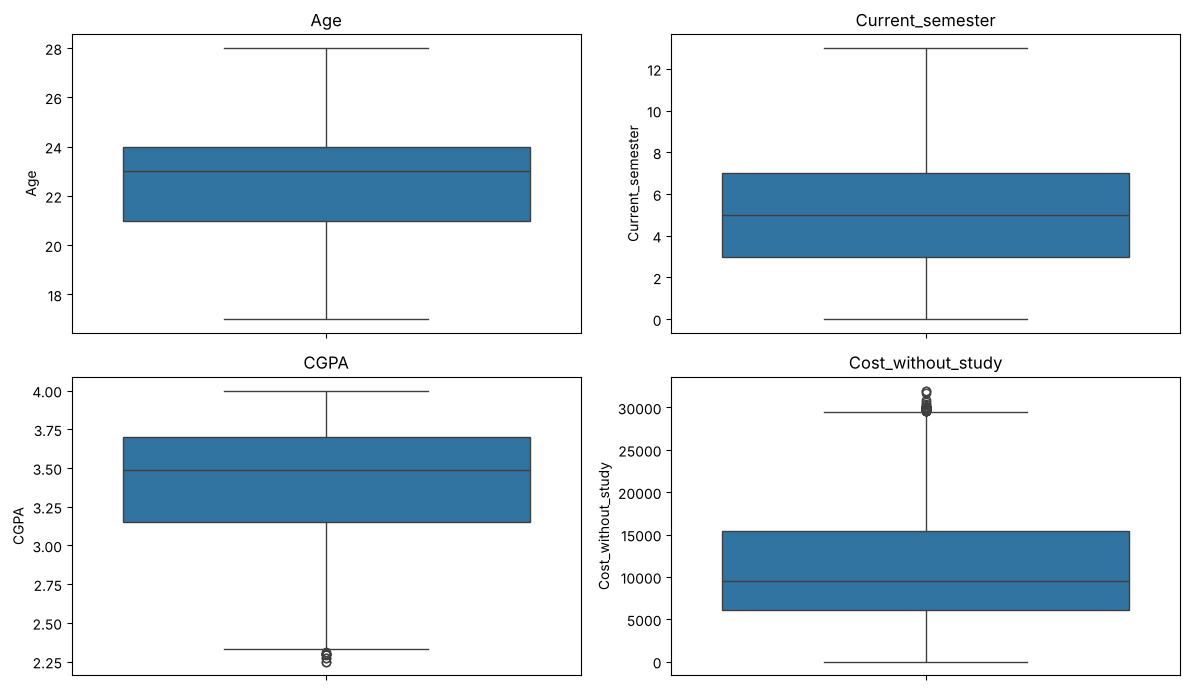

In [ ]:
plt.figure(figsize=(12, 7))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

**What to notice:** `Age` and `Current_semester` have no dots. `CGPA` has a few dots at the **low** end, and `Cost_without_study` has a few at the **high** end.

## 3.2 · IQR method and Z-score method

In [ ]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in num_cols:
    low, high = iqr_bounds(df[col])
    z = (df[col] - df[col].mean()) / df[col].std()
    rows.append([col, round(low, 2), round(high, 2), int(((df[col] < low) | (df[col] > high)).sum()), int((z.abs() > 3).sum()), round(df[col].skew(), 2)])
print(pd.DataFrame(rows, columns=["column", "lower", "upper", "IQR outliers", "Z-score outliers", "skew"]).to_string(index=False))

            column    lower    upper  IQR outliers  Z-score outliers  skew
               Age    16.50    28.50             0                 0  0.15
  Current_semester    -3.00    13.00             0                 0  0.31
              CGPA     2.32     4.53            12                 2 -0.60
Cost_without_study -7908.50 29447.50            36                 3  0.85


**What to notice:** only `CGPA` (12 by IQR) and `Cost_without_study` (36 by IQR) are flagged. There are very few of them (under 1%) and the skew is small. Age and semester have none.

## 3.3 · Look at the flagged rows: real value or mistake?

In [ ]:
print(df.sort_values("CGPA").head(5)[["Age", "Current_semester", "CGPA", "Depression"]])
print()
print("Highest costs:")
print(df["Cost_without_study"].sort_values(ascending=False).head(8).tolist())
print("Students at the maximum cost:", (df["Cost_without_study"] == df["Cost_without_study"].max()).sum())

      Age  Current_semester  CGPA Depression
2057   22                 5  2.25        Yes
2159   23                 7  2.25         No
2058   22                 8  2.27         No
2494   25                 2  2.27         No
2059   22                 6  2.29        Yes

Highest costs:
[32000, 32000, 31707, 30866, 30634, 30421, 30301, 30000]
Students at the maximum cost: 2


**What to notice:**
* The lowest CGPA is 2.25, which is a possible value on a 4.0 scale. Nobody has an impossible value such as 5.0 or -1.
* The highest costs are 32,000, 32,000, 31,707, 30,866 and so on: a **smooth, gradual end of the range**, not one wild value standing alone.

Another quick sense check: do any ages and semesters clash?

In [ ]:
young_late = df[(df["Age"] <= 18) & (df["Current_semester"] >= 8)]
print("Students aged 18 or less in semester 8 or later:", len(young_late))

Students aged 18 or less in semester 8 or later: 8


8 rows look unusual (a very young student in a late semester) but are possible (early admission), and there is no way to prove them wrong.

## 3.4 · Decision
Would **capping** change anything? Let us test it on `Cost_without_study`.

In [ ]:
low, high = iqr_bounds(df["Cost_without_study"])
capped = df["Cost_without_study"].clip(upper=high)

print("Cap at:", round(high))
print("Mean  : ", round(df["Cost_without_study"].mean(), 1), "->", round(capped.mean(), 1))
print("Median: ", df["Cost_without_study"].median(), "->", capped.median())
print("Rows changed:", int((df["Cost_without_study"] > high).sum()), "of", len(df))

Cap at: 29448
Mean  :  11243.0 -> 11237.8
Median:  9500.0 -> 9500.0
Rows changed: 36 of 4464


**What to notice:** capping moves the mean by only a small amount and changes the median not at all. The "outliers" are legitimate values at the top of a long but natural range.

| Column | What we saw | Action | Why |
|---|---|---|---|
| Age | no outliers | none | |
| Current_semester | no outliers; 42 zeros | none | Zeros may be real (new students); cannot be proved wrong |
| CGPA | 12 low values (2.25 to about 2.3) | **Keep** | Valid on a 4.0 scale; removing them would remove weaker students from the data |
| Cost_without_study | 36 high values (up to 32,000) | **Keep** | A smooth end of a natural range; capping changes almost nothing |

**Good solution:** the outlier methods are applied, the results are checked, and the decision is **keep**, with a reason. Removing flagged rows because a formula says so would lose real students.

<div style="background:#6a1b9a;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:24px;font-size:20px;font-weight:bold">Part 4 · Encoding</div>

## 4.1 · Decide the type of every text column

Encoding means turning **text into numbers**. We use the three techniques from the Encoding class, and each text column gets the technique that fits it:

| Technique | Use it when | Result |
|---|---|---|
| **Label encoding** (`LabelEncoder`) | the column has only **2 values** (and the target) | one column of 0 / 1 |
| **Ordinal encoding** (`OrdinalEncoder`) | the values have a **real order** | one column of 0, 1, 2 ... (**not** only 0 / 1) |
| **One-hot encoding** (`OneHotEncoder`) | the values have **no order** (nominal) | one new 0 / 1 column per value |

| Column | Values | Type | Technique |
|---|---|---|---|
| Gender | Female, Male | Binary | Label encoding |
| Living_style | Bachelor, Family | Binary | Label encoding |
| friend_circle | No, Yes | Binary | Label encoding |
| Family_background | Lower Middle, Middle, Rich | **Ordinal** | Ordinal encoding: 0, 1, 2 in this order |
| Health_condition | Good, Normal, Abnormal, Critical | **Ordinal** | Ordinal encoding: 0, 1, 2, 3 in this order |
| Relationship_status | Single, In a Relationship, Complicated | Nominal | One-hot encoding |
| Marital_status | Unmarried, Married, Separated | Nominal | One-hot encoding |
| Home_division | 8 divisions | Nominal | One-hot encoding |
| Depression | No, Yes | **Target** (the answer) | Label encoding (0 / 1), not scaled |

## 4.2 · Why not just use LabelEncoder for everything?

In [ ]:
from sklearn.preprocessing import LabelEncoder

for col in ["Home_division", "Family_background"]:
    le = LabelEncoder()
    le.fit(df[col])
    print(col, {name: int(code) for name, code in zip(le.classes_, le.transform(le.classes_))})
    print()

Home_division {'Barisal': 0, 'Chittagong': 1, 'Dhaka': 2, 'Khulna': 3, 'Mymensingh': 4, 'Rajshahi': 5, 'Rangpur': 6, 'Sylhet': 7}

Family_background {'Lower Middle class': 0, 'Middle class': 1, 'Rich class': 2}



**What to notice:** `LabelEncoder` numbers the values **alphabetically**.
* For `Home_division` this makes Rangpur (6) look "bigger" than Dhaka (2): a meaningless order. These columns need **one-hot**.
* For `Family_background` it gives Lower Middle 0, Middle 1, Rich 2, which happens to be the right order here, but only by luck of the alphabet. For ordinal columns we **write the order ourselves**.

## 4.3 · Label encoding: the binary columns and the target
A column with only two values becomes 0 / 1. `LabelEncoder` gives the codes in **alphabetical order**, which for these columns is: Female 0, Male 1 · Bachelor 0, Family 1 · No 0, Yes 1.

In [ ]:
binary_cols = ["Gender", "Living_style", "friend_circle", "Depression"]

df_encoded = df.copy()
for col in binary_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df[col])
    print(col, {name: int(code) for name, code in zip(le.classes_, le.transform(le.classes_))})

print()
print(df_encoded[binary_cols].head())

Gender {'Female': 0, 'Male': 1}
Living_style {'Bachelor': 0, 'Family': 1}
friend_circle {'No': 0, 'Yes': 1}
Depression {'No': 0, 'Yes': 1}

   Gender  Living_style  friend_circle  Depression
0       0             0              1           1
1       1             0              1           1
2       1             1              0           1
3       1             1              0           0
4       0             1              0           1


## 4.4 · Ordinal encoding: write the order ourselves
`OrdinalEncoder` takes a `categories` list, so **we** decide the order (lowest first) instead of letting the alphabet decide.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_cols = ["Family_background", "Health_condition"]
oe = OrdinalEncoder(categories=[
    ["Lower Middle class", "Middle class", "Rich class"],     # Family_background: low to high
    ["Good", "Normal", "Abnormal", "Critical"],               # Health_condition: best to worst
])
df_encoded[ordinal_cols] = oe.fit_transform(df[ordinal_cols]).astype(int)

for col, cats in zip(ordinal_cols, oe.categories_):
    print(col, {name: i for i, name in enumerate(cats)})

print()
print("Missing after encoding (should be 0):", int(df_encoded[ordinal_cols].isna().sum().sum()))
print(df_encoded.groupby("Health_condition")["Depression"].agg(["mean", "count"]).round(2))

Family_background {'Lower Middle class': 0, 'Middle class': 1, 'Rich class': 2}
Health_condition {'Good': 0, 'Normal': 1, 'Abnormal': 2, 'Critical': 3}

Missing after encoding (should be 0): 0
                  mean  count
Health_condition             
0                 0.00   1162
1                 0.05   1787
2                 0.55    881
3                 1.00    634


**What to notice:** the order Good < Normal < Abnormal < Critical is natural, and the share of "Yes" answers rises with it (0%, 5%, 55%, 100%), so the order we chose matches the data.

> **Caution for later modelling:** `Health_condition` is almost the same as the answer (every "Critical" student answered Yes, every "Good" student answered No). A model would look very accurate mostly because of this one column. This is worth discussing before building any model. For this preprocessing task we simply keep it and mention the risk.

## 4.5 · One-hot encoding: the nominal columns
Each value gets its own 0 / 1 column, so no false order is created.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

nominal_cols = ["Relationship_status", "Marital_status", "Home_division"]

ohe = OneHotEncoder(drop="first", sparse_output=False, dtype=int)
dummies = pd.DataFrame(ohe.fit_transform(df[nominal_cols]),
                       columns=ohe.get_feature_names_out(nominal_cols),
                       index=df.index)

# remove the original text columns and add the new 0/1 columns
df_encoded = pd.concat([df_encoded.drop(columns=nominal_cols), dummies], axis=1)

print("Shape:", df.shape, "->", df_encoded.shape)
print(list(dummies.columns))

Shape: (4464, 13) -> (4464, 21)
['Relationship_status_In a Relationship', 'Relationship_status_Single', 'Marital_status_Separated', 'Marital_status_Unmarried', 'Home_division_Chittagong', 'Home_division_Dhaka', 'Home_division_Khulna', 'Home_division_Mymensingh', 'Home_division_Rajshahi', 'Home_division_Rangpur', 'Home_division_Sylhet']


`drop="first"` removes one column for each group (it can be worked out from the others), so we avoid repeating information. 3 + 3 + 8 values give 2 + 2 + 7 = **11 dummy columns**. (`pd.get_dummies(..., drop_first=True)` gives the same table.)

## 4.6 · Check the result

In [ ]:
print("Text columns left:", list(df_encoded.select_dtypes(exclude=["number"]).columns))
print("Missing values   :", int(df_encoded.isna().sum().sum()))
print(df_encoded.dtypes.value_counts())
df_encoded.head(3)

Text columns left: []
Missing values   : 0
int64      20
float64     1
Name: count, dtype: int64


,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Separated,Marital_status_Unmarried,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,0,22,1,0,8,3.43,1,3,10113,1,0,1,0,1,1,0,0,0,0,0,0
1,1,19,1,0,2,3.70,1,2,13815,1,0,1,0,1,1,0,0,0,0,0,0
2,1,23,1,1,8,3.28,0,2,15450,1,0,1,0,1,0,1,0,0,0,0,0


## 4.7 · Is every encoded column now 0 / 1?
**No, and that is correct.** Encoding turns text into **numbers**; only some of the columns become binary.
* Label encoding and one-hot encoding give columns of 0 / 1.
* Ordinal encoding gives 0, 1, 2 (or 0 to 3), because the **order and the gaps carry meaning**. Forcing these into 0 / 1 would lose information.

In [ ]:
binary_like = [c for c in df_encoded.columns if set(df_encoded[c].unique()) <= {0, 1}]
others = [c for c in df_encoded.columns if c not in binary_like]

print("Columns with only 0 / 1 :", len(binary_like))
print(binary_like)
print()
print("Other columns           :", len(others))
for c in others:
    print(" ", c, "->", df_encoded[c].nunique(), "different values, from", df_encoded[c].min(), "to", df_encoded[c].max())

Columns with only 0 / 1 : 15
['Gender', 'Living_style', 'friend_circle', 'Depression', 'Relationship_status_In a Relationship', 'Relationship_status_Single', 'Marital_status_Separated', 'Marital_status_Unmarried', 'Home_division_Chittagong', 'Home_division_Dhaka', 'Home_division_Khulna', 'Home_division_Mymensingh', 'Home_division_Rajshahi', 'Home_division_Rangpur', 'Home_division_Sylhet']

Other columns           : 6
  Age -> 12 different values, from 17 to 28
  Family_background -> 3 different values, from 0 to 2
  Current_semester -> 14 different values, from 0 to 13
  CGPA -> 169 different values, from 2.25 to 4.0
  Health_condition -> 4 different values, from 0 to 3
  Cost_without_study -> 1970 different values, from 0 to 32000


**Decision table**
| Column | Method | Why |
|---|---|---|
| Gender, Living_style, friend_circle | Label encoding (`LabelEncoder`) | Two values only; no order issue |
| Family_background | Ordinal encoding (`OrdinalEncoder`, 0, 1, 2) | Real order: Lower Middle < Middle < Rich |
| Health_condition | Ordinal encoding (`OrdinalEncoder`, 0 to 3) | Real order, and the share of "Yes" rises with it |
| Relationship_status, Marital_status, Home_division | One-hot encoding (`OneHotEncoder`, `drop="first"`) | No order; label codes would invent one |
| Depression (target) | Label encoding (`LabelEncoder`, 0 / 1) | Model needs numbers; this is the answer, not a feature |

<div style="background:#00695c;color:#ffffff;padding:10px 18px;border-radius:8px;margin-top:24px;font-size:20px;font-weight:bold">Part 5 · Scaling with StandardScaler</div>

## 5.1 · Which columns need scaling?

In [ ]:
cont_cols = ["Age", "Current_semester", "CGPA", "Cost_without_study"]

summary = df_encoded[cont_cols].describe().T[["min", "max", "mean", "std"]]
summary["range"] = summary["max"] - summary["min"]
print(summary.round(2))

                      min      max      mean      std     range
Age                 17.00     28.0     22.62     2.02     11.00
Current_semester     0.00     13.0      5.40     2.58     13.00
CGPA                 2.25      4.0      3.41     0.39      1.75
Cost_without_study   0.00  32000.0  11242.98  6640.14  32000.00


**What to notice:** `Cost_without_study` goes up to 32,000 and has a standard deviation of about 6,600, while `CGPA` stays between 2.25 and 4.0. In any model that uses **distance** (KNN, K-means), cost would completely overpower CGPA and Age. That is why we scale.

**Decision:** scale the **4 continuous columns**. Do **not** scale the 0/1 columns (binary, dummies), the ordinal codes (small, fixed scale) or the target `Depression` (the answer is never scaled).

## 5.2 · Why scale? Cost dominates a distance

In [ ]:
two = df_encoded.loc[[0, 1], cont_cols]
print(two)

diff_sq = (two.iloc[0] - two.iloc[1]) ** 2
print()
print("Share of the squared distance, raw data (%):")
print((diff_sq / diff_sq.sum() * 100).round(1))

   Age  Current_semester  CGPA  Cost_without_study
0   22                 8  3.43               10113
1   19                 2  3.70               13815

Share of the squared distance, raw data (%):
Age                     0.0
Current_semester        0.0
CGPA                    0.0
Cost_without_study    100.0
dtype: float64


## 5.3 · StandardScaler
Each value becomes **(x − mean) / standard deviation**: mean 0 and standard deviation 1.

In [ ]:
from sklearn.preprocessing import StandardScaler

df_scaled = df_encoded.copy()
scaler = StandardScaler()
df_scaled[cont_cols] = scaler.fit_transform(df_scaled[cont_cols])

print(df_scaled[cont_cols].describe().T[["mean", "std", "min", "max"]].round(2))

                    mean  std   min   max
Age                  0.0  1.0 -2.78  2.66
Current_semester    -0.0  1.0 -2.09  2.95
CGPA                 0.0  1.0 -3.02  1.52
Cost_without_study  -0.0  1.0 -1.69  3.13


In [ ]:
# the formula by hand for one column (sklearn divides by the population std, ddof=0)
col = "CGPA"
by_hand = (df_encoded[col] - df_encoded[col].mean()) / df_encoded[col].std(ddof=0)
print("Same as the formula by hand:", np.allclose(by_hand, df_scaled[col]))

# after scaling, the same two students
two_scaled = df_scaled.loc[[0, 1], cont_cols]
diff_sq2 = (two_scaled.iloc[0] - two_scaled.iloc[1]) ** 2
print()
print("Share of the squared distance, after scaling (%):")
print((diff_sq2 / diff_sq2.sum() * 100).round(1))

Same as the formula by hand: True

Share of the squared distance, after scaling (%):
Age                   26.1
Current_semester      64.3
CGPA                   5.8
Cost_without_study     3.7
dtype: float64


**What to notice:** every scaled column has mean 0 and standard deviation 1, and the distance is no longer decided by cost alone.

## 5.4 · Scaling changes the numbers, not the shape

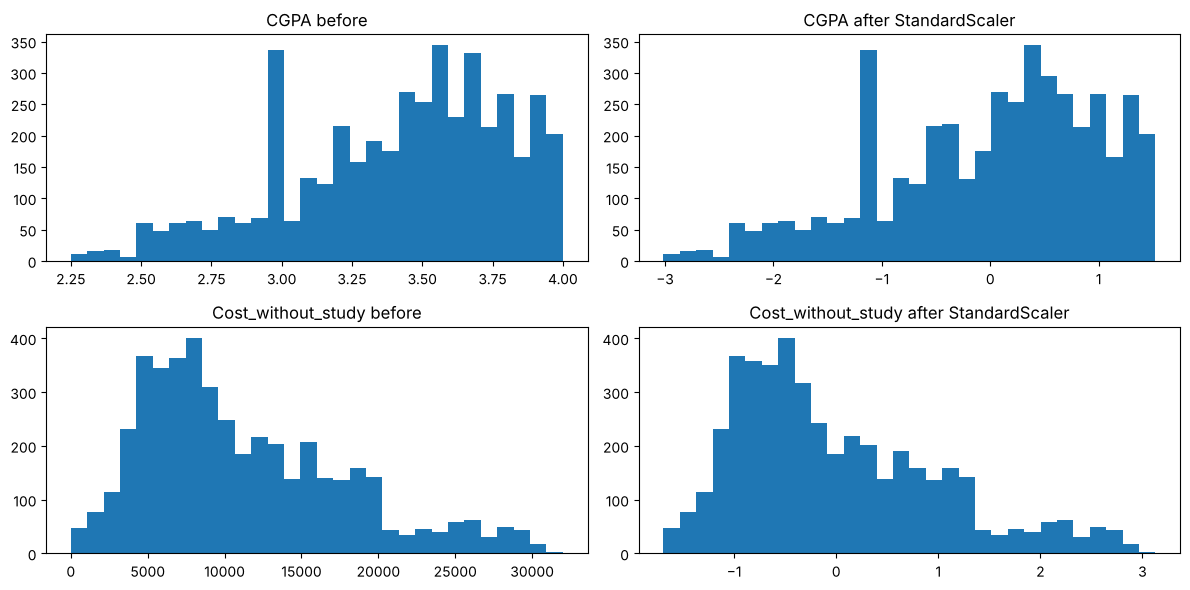

In [ ]:
plt.figure(figsize=(12, 6))
for i, col in enumerate(["CGPA", "Cost_without_study"]):
    plt.subplot(2, 2, i * 2 + 1)
    plt.hist(df_encoded[col], bins=30); plt.title(col + " before")
    plt.subplot(2, 2, i * 2 + 2)
    plt.hist(df_scaled[col], bins=30); plt.title(col + " after StandardScaler")

plt.tight_layout()
plt.show()

**What to notice:** the pictures have the same shape; only the numbers on the bottom axis change.

## 5.5 · Check the final table

In [ ]:
print("Shape:", raw.shape, "->", df_scaled.shape)
print("Missing values:", int(df_scaled.isna().sum().sum()))
print("Text columns left:", list(df_scaled.select_dtypes(exclude=["number"]).columns))
print("0/1 columns unchanged:", df_scaled[["Gender", "Living_style", "friend_circle", "Depression"]].equals(df_encoded[["Gender", "Living_style", "friend_circle", "Depression"]]))
df_scaled.head(3)

Shape: (4464, 13) -> (4464, 21)
Missing values: 0
Text columns left: []
0/1 columns unchanged: True


,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Separated,Marital_status_Unmarried,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,0,-0.306105,1,0,1.007991,0.044732,1,3,-0.170193,1,0,1,0,1,1,0,0,0,0,0,0
1,1,-1.789232,1,0,-1.319225,0.745009,1,2,0.387388,1,0,1,0,1,1,0,0,0,0,0,0
2,1,0.188270,1,1,1.007991,-0.344311,0,2,0.633645,1,0,1,0,1,0,1,0,0,0,0,0


## 5.6 · Good practice for modelling: fit on the training rows only
When we build a model, the scaler must learn (`fit`) only from the **training** data and then `transform` both train and test. Otherwise information from the test rows leaks into the training.

In [ ]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns="Depression")
y = df_encoded["Depression"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sc = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[cont_cols] = sc.fit_transform(X_train[cont_cols])      # learn from train only
X_test[cont_cols] = sc.transform(X_test[cont_cols])            # apply to test

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train mean (about 0):", X_train[cont_cols].mean().round(2).tolist())
print("Test mean  (close to 0, not exactly):", X_test[cont_cols].mean().round(2).tolist())

Train: (3571, 20) | Test: (893, 20)
Train mean (about 0): [0.0, -0.0, 0.0, -0.0]
Test mean  (close to 0, not exactly): [0.04, -0.01, -0.03, -0.02]


**What to notice:** the train columns have mean exactly 0; the test columns are only *close* to 0. That small difference is normal and correct: the test data is treated as **new, unseen** data.

---
## What was in the data (answer sheet)
* 4,464 rows, 13 columns. **No missing values and no duplicate rows.** The right action is to **check, say so, and change nothing**.
* Possible hidden issues, not provable: 42 students in semester 0 and 2 with cost 0. Kept, with a note.
* Outliers: none in Age and Semester; 12 low CGPA values and 36 high cost values by IQR. All are **valid values**, so they are **kept**.
* Encoding: label encoding for the 3 binary columns and the target, ordinal encoding for the 2 ordinal columns, one-hot encoding for the 3 nominal columns. The result is **numbers**, not only 0 / 1: the 2 ordinal columns keep 0 to 2 and 0 to 3.
* Text columns: 3 binary, 2 ordinal (Family_background, Health_condition), 3 nominal (Relationship_status, Marital_status, Home_division) and the target (Depression).
* `Health_condition` is almost the same as the answer (a leakage risk for modelling later).
* Final table: 4,464 rows, 21 columns (13 columns − 3 nominal columns + 11 dummy columns), all numbers, no missing values; 4 continuous columns scaled (mean 0, std 1).

## Check your own work
| Level | What you did |
|---|---|
| Basic | checked missing values and duplicates, drew box plots, encoded the text columns, scaled the 4 numeric columns |
| Good | used the right order for the ordinal columns, one-hot for the nominal ones, left 0/1 columns, dummies and the target unscaled, checked mean 0 and std 1 |
| Excellent | explained why nothing needed filling or dropping, tested capping before deciding to keep the outliers, noticed the Health_condition risk, fitted the scaler on the training data only, wrote a reason for every decision |

## Common mistakes
* Inventing missing values or duplicates to fix (there are none).
* Removing the flagged outliers just because IQR flagged them.
* Using `LabelEncoder` on Home_division or Marital_status (invents an order).
* Forcing an ordinal column such as Health_condition into 0 / 1, or one-hot encoding it and losing the order.
* Alphabetical codes for an ordinal column.
* Scaling the dummy columns or, worse, the target `Depression`.
* Scaling before encoding, or encoding after scaling the same column twice.
* Fitting the scaler on the whole data before splitting (leakage).

## Think about it
1. Why can the correct answer to "handle the missing values" be "there are none"?
2. When is an outlier kept, and when removed?
3. Why is `Home_division` one-hot but `Family_background` ordinal?
4. Why do we never scale the target column?
5. Why is `Health_condition` a risk when we build a model later?
6. After encoding, are all columns 0 / 1? Which ones are not, and why?